##Crank-nicolson method for example 1

In [418]:
import numpy as np
import matplotlib.pyplot as plt

### 2. Define the Computational Grid

We now define the spatial and time domains for the numerical solution.

The spatial domain is

$$
x \in [-1,1],
$$

and the final time is

$$
T=1.
$$

We divide the spatial domain into \(N_x=20\) intervals and the time interval into \(N_t=100\) time steps. The corresponding spatial and temporal step sizes are

$$
\Delta x = \frac{b-a}{N_x},
\qquad
\Delta t = \frac{T}{N_t}.
$$

The grid points are then generated using `numpy`.


In [419]:
a = -1
b = 1
T = 1

Nx = 20
Nt = 100

dx = (b - a) / Nx
dt = T / Nt

x = np.linspace(a, b, Nx + 1)
t = np.linspace(0, T, Nt + 1)


### 3. Define the Reaction Term

The reaction term in Example 1 is

$$
f(u)=c_su(1-u)(u-a).
$$

For this problem,

$$
c_s=50,\qquad a=0.5.
$$

We define this term as a Python function so that it can be evaluated at the numerical solution during each time step.


In [420]:
# Reaction term for Example 1

def reaction(u, c_s, a):
    return c_s * u * (1 - u) * (u - a)

print("Reaction term defined.")


Reaction term defined.


### 4. Set the Parameters for Example 1

For Example 1, the parameters are

$$
c_d=1,\qquad c_s=1,\qquad a=0.5,
$$

with spatial domain

$$
-1\leq x\leq 1
$$

and final time

$$
T=0.1.
$$

We use `x_left` and `x_right` for the spatial boundaries so that `a` can be used for the reaction parameter.


In [421]:
# Parameters for Example 1

x_left = -1
x_right = 1

T = 0.1

Nx = 20
Nt = 100

c_d = 1
c_s = 50
a = 0.5

dx = (x_right - x_left) / Nx
dt = T / Nt

x = np.linspace(x_left, x_right, Nx + 1)
t = np.linspace(0, T, Nt + 1)

print("Parameters set.")
print("dx =", dx)
print("dt =", dt)

Parameters set.
dx = 0.1
dt = 0.001


In [422]:
# Crank-Nicolson coefficient

r = c_d * dt / (2 * dx**2)

print("r =", r)


r = 0.04999999999999999




### Crank–Nicolson Discretisation

For the diffusion term, the Crank–Nicolson method uses the average of the spatial second derivative at time levels \(n\) and \(n+1\), while the reaction term is treated explicitly at time level \(n\):

$$
\frac{u_i^{n+1}-u_i^n}{\Delta t}
=
\frac{c_d}{2}
\left[
\frac{u_{i+1}^{n+1}-2u_i^{n+1}+u_{i-1}^{n+1}}{\Delta x^2}
+
\frac{u_{i+1}^{n}-2u_i^{n}+u_{i-1}^{n}}{\Delta x^2}
\right]
+
c_su_i^n(1-u_i^n)(u_i^n-a).
$$

Defining

$$
r=\frac{c_d\Delta t}{2\Delta x^2},
$$

and rearranging gives

$$
-r u_{i-1}^{n+1}
+(1+2r)u_i^{n+1}
-r u_{i+1}^{n+1}
=
r u_{i-1}^{n}
+(1-2r)u_i^{n}
+r u_{i+1}^{n}
+\Delta t\,c_su_i^n(1-u_i^n)(u_i^n-a).
$$

Therefore, for the interior points, the left-hand side can be written as

$$
A\mathbf{u}^{n+1}=\mathbf{b}^n,
$$

where

$$
A=
\begin{pmatrix}
1+2r & -r & 0 & \cdots & 0\\
-r & 1+2r & -r & \ddots & \vdots\\
0 & -r & 1+2r & \ddots & 0\\
\vdots & \ddots & \ddots & \ddots & -r\\
0 & \cdots & 0 & -r & 1+2r
\end{pmatrix}.
$$


In [423]:
# Crank-Nicolson matrix A

N = Nx - 1  # number of interior points

A = np.zeros((N, N))

for i in range(N):
    A[i, i] = 1 + 2*r

    if i > 0:
        A[i, i-1] = -r

    if i < N - 1:
        A[i, i+1] = -r

print("Matrix A:")
print(A)


Matrix A:
[[ 1.1  -0.05  0.    0.    0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [-0.05  1.1  -0.05  0.    0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.   -0.05  1.1  -0.05  0.    0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.   -0.05  1.1  -0.05  0.    0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.   -0.05  1.1  -0.05  0.    0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.   -0.05  1.1  -0.05  0.    0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.   -0.05  1.1  -0.05  0.    0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.   -0.05  1.1  -0.05  0.    0.    0.
   0.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    0.   -0.05  1.1

In [424]:
# Crank-Nicolson matrix B

B = np.zeros((N, N))

for i in range(N):
    B[i, i] = 1 - 2*r

    if i > 0:
        B[i, i-1] = r

    if i < N - 1:
        B[i, i+1] = r

print("Matrix B:")
print(B)


Matrix B:
[[0.9  0.05 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.05 0.9  0.05 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.05 0.9  0.05 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.05 0.9  0.05 0.   0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.05 0.9  0.05 0.   0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.05 0.9  0.05 0.   0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.05 0.9  0.05 0.   0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.05 0.9  0.05 0.   0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.05 0.9  0.05 0.   0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.   0.05 0.9  0.05 0.   0.   0.
  0.   0.   0.   0.   0.  ]
 [0.   0. 

### Initial Condition

The initial condition for Example 1 is

$$
u(x,0)=e^{-x^2}, \qquad -1\leq x\leq1.
$$

At the grid points \(x_i\), the initial numerical solution is therefore

$$
u_i^0=e^{-x_i^2}.
$$


In [425]:
# Initial condition

u = np.exp(-x**2)

print("Initial condition:")
print(u)


Initial condition:
[0.36787944 0.44485807 0.52729242 0.61262639 0.69767633 0.77880078
 0.85214379 0.91393119 0.96078944 0.99004983 1.         0.99004983
 0.96078944 0.91393119 0.85214379 0.77880078 0.69767633 0.61262639
 0.52729242 0.44485807 0.36787944]


In [426]:
# Boundary conditions

boundary_value = np.exp(-1)

u[0] = boundary_value
u[-1] = boundary_value

print("Boundary value =", boundary_value)

Boundary value = 0.36787944117144233


In [427]:
# Reaction contribution

reaction_term = dt * reaction(u[1:-1], c_s, a)

print("Reaction contribution:")
print(reaction_term)

Reaction contribution:
[-0.00068089  0.00034014  0.0013364   0.00208473  0.00240145  0.00221841
  0.00162801  0.00086797  0.00024138  0.          0.00024138  0.00086797
  0.00162801  0.00221841  0.00240145  0.00208473  0.0013364   0.00034014
 -0.00068089]


In [428]:
# Boundary contribution to the right-hand side

boundary_contribution = np.zeros(N)

boundary_contribution[0] = r * u[0] + r * u[0]
boundary_contribution[-1] = r * u[-1] + r * u[-1]

print("Boundary contribution:")
print(boundary_contribution)


Boundary contribution:
[0.03678794 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.03678794]


In [429]:
# Construct the right-hand side vector

rhs = B @ u[1:-1] + reaction_term + boundary_contribution

print("Right-hand side:")
print(rhs)

Right-hand side:
[0.46284393 0.52777754 0.61394859 0.69956479 0.78081316 0.85378442
 0.91481274 0.96077751 0.9893257  0.99900498 0.9893257  0.96077751
 0.91481274 0.85378442 0.78081316 0.69956479 0.61394859 0.52777754
 0.46284393]


In [430]:
# Solve for the next time step

u_new_interior = np.linalg.solve(A, rhs)

print("Interior solution at next time step:")
print(u_new_interior)


Interior solution at next time step:
[0.44476356 0.52791974 0.6139199  0.69934616 0.78039991 0.85318863
 0.91406147 0.95990893 0.98838466 0.9980395  0.98838466 0.95990893
 0.91406147 0.85318863 0.78039991 0.69934616 0.6139199  0.52791974
 0.44476356]


In [431]:
# Construct the full solution at the next time step

u_new = np.zeros(Nx + 1)

u_new[0] = boundary_value
u_new[-1] = boundary_value
u_new[1:-1] = u_new_interior

print("Full solution at t =", dt)
print(u_new)


Full solution at t = 0.001
[0.36787944 0.44476356 0.52791974 0.6139199  0.69934616 0.78039991
 0.85318863 0.91406147 0.95990893 0.98838466 0.9980395  0.98838466
 0.95990893 0.91406147 0.85318863 0.78039991 0.69934616 0.6139199
 0.52791974 0.44476356 0.36787944]


In [432]:
# Update the solution for the next time step

u = u_new.copy()




In [433]:
# Reset to the true initial condition

u = np.exp(-x**2)
u[0] = boundary_value
u[-1] = boundary_value

U_CN = np.zeros((Nt + 1, Nx + 1))
U_CN[0, :] = u

for n in range(Nt):

    reaction_term = dt * reaction(u[1:-1], c_s, a)

    boundary_contribution = np.zeros(N)
    boundary_contribution[0] = 2 * r * boundary_value
    boundary_contribution[-1] = 2 * r * boundary_value

    rhs = B @ u[1:-1] + reaction_term + boundary_contribution

    u_new_interior = np.linalg.solve(A, rhs)

    u_new = np.zeros(Nx + 1)
    u_new[0] = boundary_value
    u_new[-1] = boundary_value
    u_new[1:-1] = u_new_interior

    u = u_new.copy()
    U_CN[n + 1, :] = u



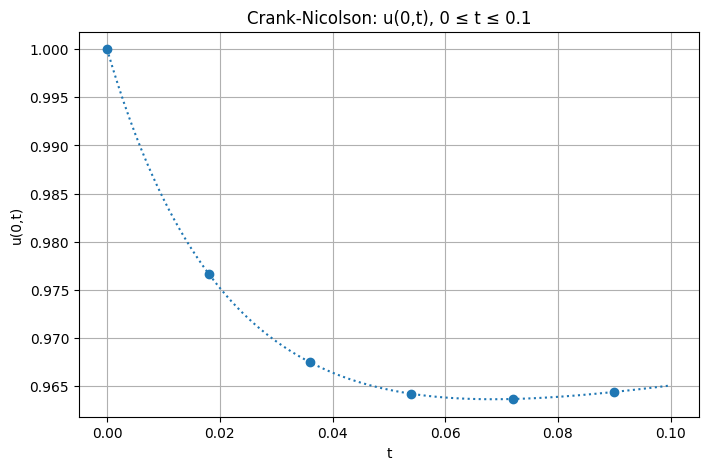

In [434]:
# Plot u(0,t) for 0 <= t <= 0.1

x0_index = np.argmin(np.abs(x - 0))
mask = t <= 0.1

plt.figure(figsize=(8, 5))

plt.plot(t[mask], U_CN[mask, x0_index], marker ="o",markevery=18, linestyle=':')

plt.xlabel("t")
plt.ylabel("u(0,t)")
plt.title("Crank-Nicolson: u(0,t), 0 ≤ t ≤ 0.1")
plt.grid()

plt.show()

In [435]:
# Fine grid for the reference solution

Nx_ref = 200
Nt_ref = 1000

dx_ref = (x_right - x_left) / Nx_ref
dt_ref = T / Nt_ref

x_ref = np.linspace(x_left, x_right, Nx_ref + 1)
t_ref = np.linspace(0, T, Nt_ref + 1)

print("dx_ref =", dx_ref)
print("dt_ref =", dt_ref)

dx_ref = 0.01
dt_ref = 0.0001


In [436]:
# Reference solution using Crank-Nicolson

N_ref = Nx_ref - 1

r_ref = c_d * dt_ref / (2 * dx_ref**2)

A_ref = np.zeros((N_ref, N_ref))
B_ref = np.zeros((N_ref, N_ref))

for i in range(N_ref):
    A_ref[i, i] = 1 + 2*r_ref
    B_ref[i, i] = 1 - 2*r_ref

    if i > 0:
        A_ref[i, i-1] = -r_ref
        B_ref[i, i-1] = r_ref

    if i < N_ref - 1:
        A_ref[i, i+1] = -r_ref
        B_ref[i, i+1] = r_ref

u_ref = np.exp(-x_ref**2)

boundary_value_ref = np.exp(-1)

u_ref[0] = boundary_value_ref
u_ref[-1] = boundary_value_ref

U_ref = np.zeros((Nt_ref + 1, Nx_ref + 1))
U_ref[0, :] = u_ref

for n in range(Nt_ref):

    reaction_term_ref = dt_ref * reaction(u_ref[1:-1], c_s, a)

    boundary_contribution_ref = np.zeros(N_ref)
    boundary_contribution_ref[0] = 2 * r_ref * boundary_value_ref
    boundary_contribution_ref[-1] = 2 * r_ref * boundary_value_ref

    rhs_ref = B_ref @ u_ref[1:-1] + reaction_term_ref + boundary_contribution_ref

    u_new_interior_ref = np.linalg.solve(A_ref, rhs_ref)

    u_new_ref = np.zeros(Nx_ref + 1)
    u_new_ref[0] = boundary_value_ref
    u_new_ref[-1] = boundary_value_ref
    u_new_ref[1:-1] = u_new_interior_ref

    u_ref = u_new_ref.copy()
    U_ref[n + 1, :] = u_ref



In [437]:
# Maximum absolute error of the Crank-Nicolson solution

U_ref_coarse = U_ref[::10, ::10]

absolute_error = np.abs(U_CN - U_ref_coarse)

max_absolute_error = np.max(absolute_error)

print("Maximum absolute error =", max_absolute_error)


Maximum absolute error = 0.0012836422890000199


In [438]:
# Grid sizes for the maximum error analysis

Nx_values = [5, 10, 15, 20, 25, 30]

max_errors = []

print("Grid sizes:", Nx_values)


Grid sizes: [5, 10, 15, 20, 25, 30]


In [414]:
# Calculate maximum absolute error for each grid size

max_errors = []

for Nx_test in Nx_values:

    Nt_test = int(500 * Nx_test)

    dx_test = (x_right - x_left) / Nx_test
    dt_test = T / Nt_test

    x_test = np.linspace(x_left, x_right, Nx_test + 1)

    N_test = Nx_test - 1
    r_test = c_d * dt_test / (2 * dx_test**2)

    A_test = np.zeros((N_test, N_test))
    B_test = np.zeros((N_test, N_test))

    for i in range(N_test):
        A_test[i, i] = 1 + 2*r_test
        B_test[i, i] = 1 - 2*r_test

        if i > 0:
            A_test[i, i-1] = -r_test
            B_test[i, i-1] = r_test

        if i < N_test - 1:
            A_test[i, i+1] = -r_test
            B_test[i, i+1] = r_test

    u_test = np.exp(-x_test**2)
    u_test[0] = boundary_value
    u_test[-1] = boundary_value

    for n in range(Nt_test):

        reaction_term_test = dt_test * reaction(u_test[1:-1], c_s, a)

        boundary_contribution_test = np.zeros(N_test)
        boundary_contribution_test[0] = 2 * r_test * boundary_value
        boundary_contribution_test[-1] = 2 * r_test * boundary_value

        rhs_test = (
            B_test @ u_test[1:-1]
            + reaction_term_test
            + boundary_contribution_test
        )

        u_new_interior_test = np.linalg.solve(A_test, rhs_test)

        u_new_test = np.zeros(Nx_test + 1)
        u_new_test[0] = boundary_value
        u_new_test[-1] = boundary_value
        u_new_test[1:-1] = u_new_interior_test

        u_test = u_new_test

    # Interpolate the reference solution onto the coarse grid
    u_reference = np.interp(x_test, x_ref, U_ref[-1, :])

    error = np.abs(u_test - u_reference)
    max_error = np.max(error)

    max_errors.append(max_error)

    print("Nx =", Nx_test, "Maximum error =", max_error)

Nx = 5 Maximum error = 0.026371253233171243
Nx = 10 Maximum error = 0.005630507893170988
Nx = 15 Maximum error = 0.0024377023035737633
Nx = 20 Maximum error = 0.001401043489874243
Nx = 25 Maximum error = 0.0009054504785189765
Nx = 30 Maximum error = 0.0006490246470726158


In [415]:
Nx_values = np.array(Nx_values)
max_errors = np.array(max_errors)

### Convergence Analysis

we need to  determine the convergence of the Crank–Nicolson method, we compare the maximum absolute error obtained using different spatial grid sizes.



In [416]:
dx_values = (x_right - x_left) / Nx_values

convergence_orders = []

for i in range(1, len(Nx_values)):
    p = np.log(max_errors[i-1] / max_errors[i]) / np.log(dx_values[i-1] / dx_values[i])
    convergence_orders.append(p)

print("Convergence orders:")
for i, p in enumerate(convergence_orders, start=1):
    print(f"{Nx_values[i-1]} -> {Nx_values[i]}: p = {p:.4f}")

Convergence orders:
5 -> 10: p = 2.2276
10 -> 15: p = 2.0647
15 -> 20: p = 1.9252
20 -> 25: p = 1.9563
25 -> 30: p = 1.8262


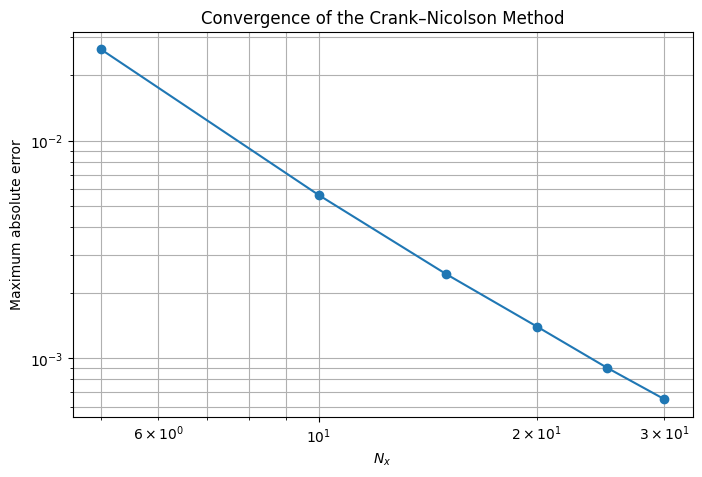

In [417]:
plt.figure(figsize=(8, 5))

plt.loglog(Nx_values, max_errors, 'o-')

plt.xlabel("$N_x$")
plt.ylabel("Maximum absolute error")
plt.title("Convergence of the Crank–Nicolson Method")
plt.grid(True, which="both")

plt.show()

### Discussion of Results

The Crank–Nicolson method gave good results for Example 1. As \(N_x\) increased, the maximum absolute error decreased.

| \(N_x\) | Maximum absolute error | Convergence order |
|---:|---:|---:|
| 5  | 0.0263713 | — |
| 10 | 0.0056305 | 2.2276 |
| 15 | 0.0024377 | 2.0647 |
| 20 | 0.0014010 | 1.9252 |
| 25 | 0.0009055 | 1.9563 |
| 30 | 0.0006490 | 1.8262 |

The error decreases as the grid is refined. The convergence order is close to \(2\), which shows that our Crank–Nicolson method has approximately second-order convergence:

\[
E_{\max}=O(\Delta x^2).
\]

For comparison, FTCS is simpler because it calculates the new solution directly from the previous time step. However, FTCS has a more restrictive stability condition. Crank–Nicolson is more stable for the diffusion part and gives second-order accuracy in time.

The errors reported in the paper are:

| \(N_x\) | Error from the paper |
|---:|---:|
| 5  | 0.0291456 |
| 10 | 0.0001561 |
| 15 | 0.0001499 |
| 20 | 0.0001495 |
| 25 | 0.0001495 |
| 30 | 0.0001495 |

Our errors decrease steadily from \(0.0263713\) at \(N_x=5\) to \(0.0006490\) at \(N_x=30\). The paper also shows smaller errors as the grid is refined, but the errors then become almost constant.

The errors from our method and the paper are not exactly the same. This may be because the paper uses a different numerical method, time step, or reference solution. Therefore, the values should not be compared directly as if they were calculated under exactly the same conditions.

 the Crank–Nicolson results show that the method is converging as the grid is refined, with an observed convergence order of approximately \(2\).